In [27]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

SEED = 42

print("All libraries imported successfully!")


All libraries imported successfully!


In [28]:

!pip -q install kagglehub

import kagglehub
import glob
import os

dataset_path = kagglehub.dataset_download(
    "shivamb/real-or-fake-fake-jobposting-prediction"
)

csv_files = glob.glob(
    os.path.join(dataset_path, "**", "*.csv"),
    recursive=True
)

print("Dataset downloaded successfully!")
print("CSV files:", csv_files)


Using Colab cache for faster access to the 'real-or-fake-fake-jobposting-prediction' dataset.
Dataset downloaded successfully!
CSV files: ['/kaggle/input/real-or-fake-fake-jobposting-prediction/fake_job_postings.csv']


In [29]:

df = pd.read_csv(csv_files[0])

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())


Dataset loaded successfully!
Dataset Shape: (17880, 18)

First 5 Rows:


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0



Column Names:
['job_id', 'title', 'location', 'department', 'salary_range', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent']


Missing Values Analysis:


,Missing Count,Missing Percentage
salary_range,15012,83.96
department,11547,64.58
required_education,8105,45.33
benefits,7212,40.34
required_experience,7050,39.43
function,6455,36.10
industry,4903,27.42
employment_type,3471,19.41
company_profile,3308,18.50
requirements,2696,15.08



Class Distribution:
Real Jobs (0): 17014
Fake Jobs (1): 866

Class Percentages:
fraudulent
0    95.16
1     4.84
Name: proportion, dtype: float64


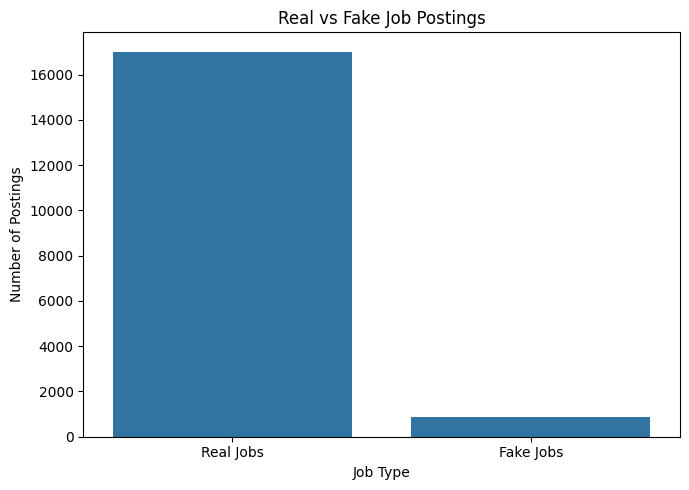

In [30]:

# Missing values analysis
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

missing = missing.sort_values(
    by="Missing Percentage", ascending=False
)

print("Missing Values Analysis:")
display(missing)

# Class distribution
class_counts = df["fraudulent"].value_counts().sort_index()

print("\nClass Distribution:")
print("Real Jobs (0):", class_counts[0])
print("Fake Jobs (1):", class_counts[1])

print("\nClass Percentages:")
print((df["fraudulent"].value_counts(normalize=True) * 100).round(2))

# Class distribution visualization
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="fraudulent")
plt.xticks([0, 1], ["Real Jobs", "Fake Jobs"])
plt.title("Real vs Fake Job Postings")
plt.xlabel("Job Type")
plt.ylabel("Number of Postings")
plt.tight_layout()
plt.show()


Text Statistics by Job Type:


text_length          word_count       
                   mean  median        mean median
fraudulent                                        
0           2700.587575  2560.5  379.491066  355.0
1           2078.638568  1656.5  282.332564  224.5

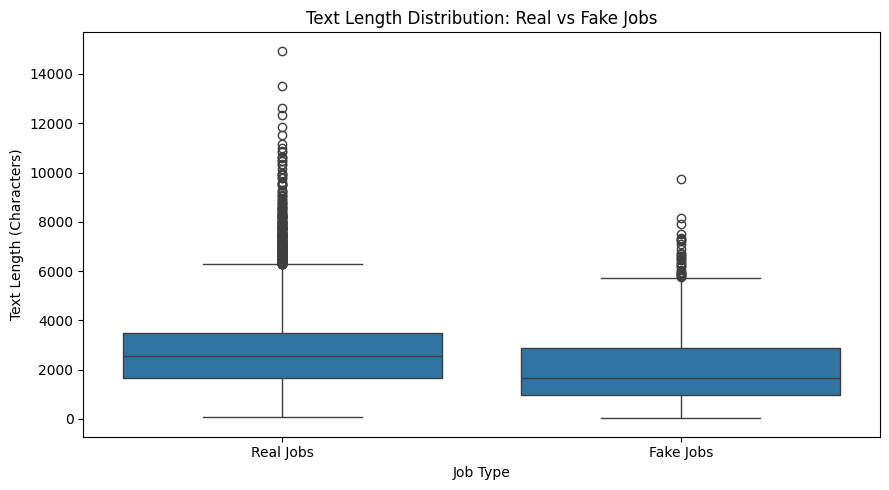

In [31]:

# Combine important text columns
text_columns = [
    "title",
    "company_profile",
    "description",
    "requirements",
    "benefits"
]

df["combined_text"] = (
    df[text_columns]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
)

# Calculate text length and word count
df["text_length"] = df["combined_text"].str.len()

df["word_count"] = (
    df["combined_text"]
    .str.split()
    .str.len()
)

# Compare real and fake jobs
print("Text Statistics by Job Type:")

text_stats = df.groupby("fraudulent")[
    ["text_length", "word_count"]
].agg(["mean", "median"])

display(text_stats)

# Visualize text length distribution
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="fraudulent",
    y="text_length"
)

plt.xticks([0, 1], ["Real Jobs", "Fake Jobs"])
plt.title("Text Length Distribution: Real vs Fake Jobs")
plt.xlabel("Job Type")
plt.ylabel("Text Length (Characters)")
plt.tight_layout()
plt.show()


Fraud Rate by Company Logo:


,fraudulent
has_company_logo,
0,15.93
1,1.99



Fraud Rate by Employment Type:


,count,fraud_rate_percent
employment_type,,
Contract,1524,2.89
Full-time,11620,4.22
Other,227,6.61
Part-time,797,9.28
Temporary,241,0.83
NaN,3471,6.94


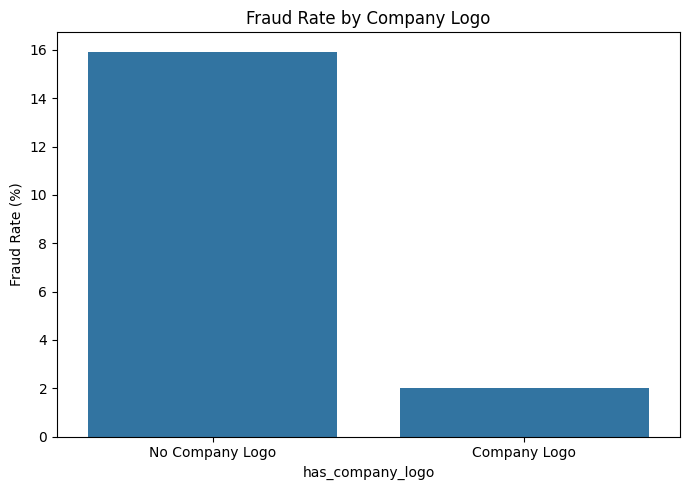

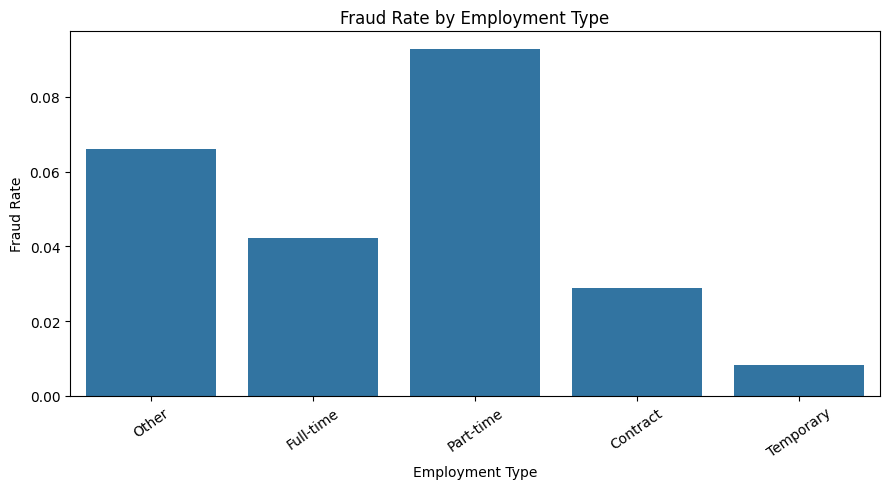

In [32]:

# Fraud rate by company logo
logo_fraud = df.groupby("has_company_logo")["fraudulent"].mean() * 100

print("Fraud Rate by Company Logo:")
display(logo_fraud.round(2))

# Fraud rate by employment type
employment_fraud = (
    df.groupby("employment_type", dropna=False)["fraudulent"]
    .agg(["count", "mean"])
)

employment_fraud["fraud_rate_percent"] = (
    employment_fraud["mean"] * 100
)

employment_fraud = employment_fraud.drop(columns="mean")

print("\nFraud Rate by Employment Type:")
display(employment_fraud.round(2))

# Visualization 1
plt.figure(figsize=(7, 5))

sns.barplot(
    x=logo_fraud.index,
    y=logo_fraud.values
)

plt.xticks([0, 1], ["No Company Logo", "Company Logo"])
plt.ylabel("Fraud Rate (%)")
plt.title("Fraud Rate by Company Logo")
plt.tight_layout()
plt.show()

# Visualization 2
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="employment_type",
    y="fraudulent",
    errorbar=None
)

plt.ylabel("Fraud Rate")
plt.xlabel("Employment Type")
plt.title("Fraud Rate by Employment Type")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()


In [33]:

# Create a working copy
data = df.copy()

# Remove unnecessary ID column
data = data.drop(columns=["job_id"])

# Define text and structured columns
text_columns = [
    "title",
    "company_profile",
    "description",
    "requirements",
    "benefits"
]

categorical_columns = [
    "location",
    "department",
    "salary_range",
    "employment_type",
    "required_experience",
    "required_education",
    "industry",
    "function"
]

numeric_columns = [
    "telecommuting",
    "has_company_logo",
    "has_questions",
    "text_length",
    "word_count"
]

# Target variable
y = data["fraudulent"]

# Input features
X = data.drop(columns=["fraudulent"])

print("Feature preparation completed!")
print("Total rows:", X.shape[0])
print("Total input columns:", X.shape[1])
print("Real jobs:", (y == 0).sum())
print("Fake jobs:", (y == 1).sum())


Feature preparation completed!
Total rows: 17880
Total input columns: 19
Real jobs: 17014
Fake jobs: 866


In [34]:

# First split: 85% temporary data, 15% test data
X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=SEED,
    stratify=y
)

# Second split: 70% train, 15% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.15 / 0.85,
    random_state=SEED,
    stratify=y_temp
)

# Display split sizes
print("Training Set:", X_train.shape)
print("Validation Set:", X_val.shape)
print("Testing Set:", X_test.shape)

print("\nFake Job Distribution:")
print("Training:", y_train.value_counts().to_dict())
print("Validation:", y_val.value_counts().to_dict())
print("Testing:", y_test.value_counts().to_dict())

print("\nSplit Percentages:")
print("Training:", round(len(X_train) / len(X) * 100, 2), "%")
print("Validation:", round(len(X_val) / len(X) * 100, 2), "%")
print("Testing:", round(len(X_test) / len(X) * 100, 2), "%")


Training Set: (12516, 19)
Validation Set: (2682, 19)
Testing Set: (2682, 19)

Fake Job Distribution:
Training: {0: 11910, 1: 606}
Validation: {0: 2552, 1: 130}
Testing: {0: 2552, 1: 130}

Split Percentages:
Training: 70.0 %
Validation: 15.0 %
Testing: 15.0 %


In [35]:

# Create separate copies for each dataset
X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()

# Fill missing text values and combine text columns
for dataset in [X_train, X_val, X_test]:

    dataset["combined_text"] = (
        dataset[text_columns]
        .fillna("")
        .astype(str)
        .agg(" ".join, axis=1)
    )

    # Calculate text statistics
    dataset["text_length"] = dataset["combined_text"].str.len()

    dataset["word_count"] = (
        dataset["combined_text"].str.split().str.len()
    )

print("Text preparation completed!")

print("Training text sample:")
print(X_train["combined_text"].iloc[0][:300])

print("\nStructured features:", numeric_columns + categorical_columns)
print("Text feature: combined_text")


Text preparation completed!
Training text sample:
Technical Manager Luxury British cocoa grower and chocolatier, Hotel Chocolat, was founded in 2004 to make exciting chocolate with three guiding principles – authenticity, originality and ethics – which remain central to the brand’s success today To own and drive compliance of a safe, legal, quality

Structured features: ['telecommuting', 'has_company_logo', 'has_questions', 'text_length', 'word_count', 'location', 'department', 'salary_range', 'employment_type', 'required_experience', 'required_education', 'industry', 'function']
Text feature: combined_text


In [36]:

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import TfidfVectorizer

# Numeric preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=10
    ))
])

# Structured features
structured_preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

# Text preprocessing
text_preprocessor = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    stop_words="english",
    min_df=2,
    sublinear_tf=True
)

print("Structured preprocessing pipeline created!")
print("Text TF-IDF pipeline created!")


Structured preprocessing pipeline created!
Text TF-IDF pipeline created!


In [37]:

# Create a separate non-negative structured pipeline
numeric_pipeline_nb = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    ))
])

categorical_pipeline_nb = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=10
    ))
])

structured_preprocessor_nb = ColumnTransformer([
    ("numeric", numeric_pipeline_nb, numeric_columns),
    ("categorical", categorical_pipeline_nb, categorical_columns)
])

# Non-negative combined preprocessing
combined_preprocessor_nb = ColumnTransformer([
    ("text", clone(text_preprocessor), "combined_text"),
    ("structured", structured_preprocessor_nb,
     numeric_columns + categorical_columns)
])

# Train Complement Naive Bayes
nb_pipeline = Pipeline([
    ("preprocessing", combined_preprocessor_nb),
    ("classifier", ComplementNB())
])

nb_pipeline.fit(X_train, y_train)

trained_models["Complement Naive Bayes"] = nb_pipeline

print("Complement Naive Bayes trained successfully!")
print("\nAll three models are now ready!")


Complement Naive Bayes trained successfully!

All three models are now ready!


In [38]:

from sklearn.metrics import average_precision_score

validation_results = []

for name, model in trained_models.items():

    # Get prediction scores
    if hasattr(model.named_steps["classifier"], "predict_proba"):
        scores = model.predict_proba(X_val)[:, 1]
    else:
        scores = model.decision_function(X_val)

    # Default threshold / decision boundary
    predictions = model.predict(X_val)

    # Calculate metrics
    precision = precision_score(y_val, predictions, zero_division=0)
    recall = recall_score(y_val, predictions, zero_division=0)
    f1 = f1_score(y_val, predictions, zero_division=0)
    pr_auc = average_precision_score(y_val, scores)
    roc_auc = roc_auc_score(y_val, scores)

    validation_results.append({
        "Model": name,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "PR-AUC": pr_auc,
        "ROC-AUC": roc_auc
    })

validation_df = pd.DataFrame(validation_results)

print("Validation Performance:")
display(validation_df.round(4))


Validation Performance:


,Model,Precision,Recall,F1-Score,PR-AUC,ROC-AUC
0,Logistic Regression,0.6409,0.8923,0.7460,0.8656,0.9908
1,Linear SVM,0.8626,0.8692,0.8659,0.9279,0.9932
2,Complement Naive Bayes,0.4444,0.2462,0.3168,0.3729,0.8161


Best SVM Threshold: 0.018
Validation Precision: 0.876
Validation Recall: 0.8692
Validation F1-Score: 0.8726


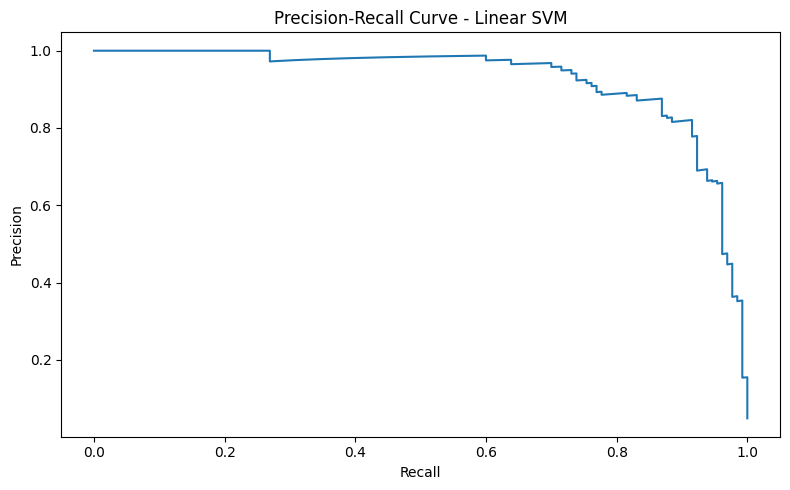

In [39]:

from sklearn.metrics import precision_recall_curve

# Get SVM decision scores on validation data
svm_model = trained_models["Linear SVM"]

val_scores = svm_model.decision_function(X_val)

# Calculate precision and recall at different thresholds
precisions, recalls, thresholds = precision_recall_curve(
    y_val,
    val_scores
)

# Calculate F1 for each threshold
f1_values = (
    2 * precisions[:-1] * recalls[:-1]
    / (precisions[:-1] + recalls[:-1] + 1e-10)
)

# Find threshold with highest validation F1
best_index = np.argmax(f1_values)
best_threshold = thresholds[best_index]

print("Best SVM Threshold:", round(best_threshold, 4))
print("Validation Precision:", round(precisions[best_index], 4))
print("Validation Recall:", round(recalls[best_index], 4))
print("Validation F1-Score:", round(f1_values[best_index], 4))

# Plot Precision-Recall curve
plt.figure(figsize=(8, 5))
plt.plot(recalls, precisions)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Linear SVM")
plt.tight_layout()
plt.show()


FINAL TEST RESULTS - LINEAR SVM
--------------------------------
Threshold: 0.018
Accuracy: 0.9903
Precision: 0.9561
Recall: 0.8385
F1-Score: 0.8934
PR-AUC: 0.9274
ROC-AUC: 0.9853

Classification Report:
              precision    recall  f1-score   support

   Real Jobs       0.99      1.00      0.99      2552
   Fake Jobs       0.96      0.84      0.89       130

    accuracy                           0.99      2682
   macro avg       0.97      0.92      0.94      2682
weighted avg       0.99      0.99      0.99      2682



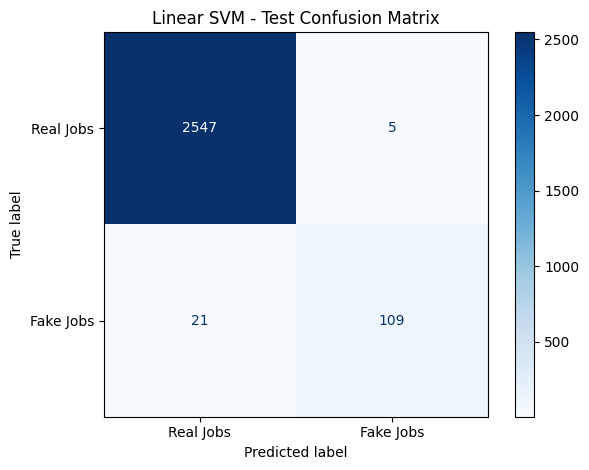

In [40]:

from sklearn.metrics import (
    average_precision_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Predict test scores using trained SVM
test_scores = svm_model.decision_function(X_test)

# Apply selected validation threshold
test_predictions = (
    test_scores >= best_threshold
).astype(int)

# Calculate final metrics
test_precision = precision_score(
    y_test, test_predictions, zero_division=0
)

test_recall = recall_score(
    y_test, test_predictions, zero_division=0
)

test_f1 = f1_score(
    y_test, test_predictions, zero_division=0
)

test_pr_auc = average_precision_score(
    y_test, test_scores
)

test_roc_auc = roc_auc_score(
    y_test, test_scores
)

print("FINAL TEST RESULTS - LINEAR SVM")
print("--------------------------------")
print("Threshold:", round(best_threshold, 4))
print("Accuracy:", round(accuracy_score(y_test, test_predictions), 4))
print("Precision:", round(test_precision, 4))
print("Recall:", round(test_recall, 4))
print("F1-Score:", round(test_f1, 4))
print("PR-AUC:", round(test_pr_auc, 4))
print("ROC-AUC:", round(test_roc_auc, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_predictions,
    target_names=["Real Jobs", "Fake Jobs"]
))

# Confusion Matrix
cm = confusion_matrix(y_test, test_predictions)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Real Jobs", "Fake Jobs"]
).plot(cmap="Blues", values_format="d")

plt.title("Linear SVM - Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [41]:

from sklearn.preprocessing import FunctionTransformer

# Extract combined_text as a one-dimensional series
text_only_preprocessor = Pipeline([
    ("extract_text", FunctionTransformer(
        lambda data: data["combined_text"],
        validate=False
    )),
    ("tfidf", clone(text_preprocessor))
])

# Replace text-only preprocessor
ablation_preprocessors["Text Only"] = text_only_preprocessor

# Train Text-only Linear SVM
text_only_model = Pipeline([
    ("preprocessing", text_only_preprocessor),
    ("classifier", LinearSVC(
        class_weight="balanced",
        random_state=SEED
    ))
])

print("Training Text-only model...")

text_only_model.fit(X_train, y_train)

print("Text-only model trained successfully!")

# Save trained model
ablation_models["Text Only"] = text_only_model


Training Text-only model...
Text-only model trained successfully!


In [42]:

# Validation predictions and threshold selection
val_scores = text_only_model.decision_function(X_val)

p, r, thresholds = precision_recall_curve(y_val, val_scores)

f1_values = (
    2 * p[:-1] * r[:-1]
    / (p[:-1] + r[:-1] + 1e-10)
)

best_idx = np.argmax(f1_values)
text_threshold = thresholds[best_idx]

# Test evaluation
test_scores = text_only_model.decision_function(X_test)
test_preds = (test_scores >= text_threshold).astype(int)

text_only_result = {
    "Feature Set": "Text Only",
    "Threshold": text_threshold,
    "Precision": precision_score(y_test, test_preds, zero_division=0),
    "Recall": recall_score(y_test, test_preds, zero_division=0),
    "F1-Score": f1_score(y_test, test_preds, zero_division=0),
    "PR-AUC": average_precision_score(y_test, test_scores),
    "ROC-AUC": roc_auc_score(y_test, test_scores)
}

# Update ablation results
ablation_results = [
    result for result in ablation_results
    if result["Feature Set"] != "Text Only"
]

ablation_results.append(text_only_result)

ablation_df = pd.DataFrame(ablation_results)

display(ablation_df.round(4))


,Feature Set,Threshold,Precision,Recall,F1-Score,PR-AUC,ROC-AUC
0,Structured Only,0.4342,0.4295,0.5154,0.4685,0.4656,0.9076
1,Combined,0.0180,0.9561,0.8385,0.8934,0.9274,0.9853
2,Text Only,-0.1350,0.8992,0.8923,0.8958,0.9320,0.9852


In [43]:

# Build and train Combined model
combined_model = Pipeline([
    ("preprocessing", clone(combined_preprocessor)),
    ("classifier", LinearSVC(
        class_weight="balanced",
        random_state=SEED
    ))
])

print("Training Combined model...")

combined_model.fit(X_train, y_train)

print("Combined model trained successfully!")

# Select threshold using validation data
val_scores = combined_model.decision_function(X_val)

p, r, thresholds = precision_recall_curve(y_val, val_scores)

f1_values = (
    2 * p[:-1] * r[:-1]
    / (p[:-1] + r[:-1] + 1e-10)
)

best_idx = np.argmax(f1_values)
combined_threshold = thresholds[best_idx]

# Evaluate on test data
test_scores = combined_model.decision_function(X_test)
test_preds = (test_scores >= combined_threshold).astype(int)

combined_result = {
    "Feature Set": "Combined",
    "Threshold": combined_threshold,
    "Precision": precision_score(y_test, test_preds, zero_division=0),
    "Recall": recall_score(y_test, test_preds, zero_division=0),
    "F1-Score": f1_score(y_test, test_preds, zero_division=0),
    "PR-AUC": average_precision_score(y_test, test_scores),
    "ROC-AUC": roc_auc_score(y_test, test_scores)
}

# Store model and update comparison
ablation_models["Combined"] = combined_model

ablation_results = [
    result for result in ablation_results
    if result["Feature Set"] != "Combined"
]

ablation_results.append(combined_result)

ablation_df = pd.DataFrame(ablation_results)

print("\nFINAL ABLATION STUDY")
display(ablation_df.round(4))


Training Combined model...
Combined model trained successfully!

FINAL ABLATION STUDY


,Feature Set,Threshold,Precision,Recall,F1-Score,PR-AUC,ROC-AUC
0,Structured Only,0.4342,0.4295,0.5154,0.4685,0.4656,0.9076
1,Text Only,-0.1350,0.8992,0.8923,0.8958,0.9320,0.9852
2,Combined,0.0180,0.9561,0.8385,0.8934,0.9274,0.9853


In [44]:

# Build and train Combined model
combined_model = Pipeline([
    ("preprocessing", clone(combined_preprocessor)),
    ("classifier", LinearSVC(
        class_weight="balanced",
        random_state=SEED
    ))
])

print("Training Combined model...")

combined_model.fit(X_train, y_train)

print("Combined model trained successfully!")

# Select threshold using validation data
val_scores = combined_model.decision_function(X_val)

p, r, thresholds = precision_recall_curve(y_val, val_scores)

f1_values = (
    2 * p[:-1] * r[:-1]
    / (p[:-1] + r[:-1] + 1e-10)
)

best_idx = np.argmax(f1_values)
combined_threshold = thresholds[best_idx]

# Evaluate on test data
test_scores = combined_model.decision_function(X_test)
test_preds = (test_scores >= combined_threshold).astype(int)

combined_result = {
    "Feature Set": "Combined",
    "Threshold": combined_threshold,
    "Precision": precision_score(y_test, test_preds, zero_division=0),
    "Recall": recall_score(y_test, test_preds, zero_division=0),
    "F1-Score": f1_score(y_test, test_preds, zero_division=0),
    "PR-AUC": average_precision_score(y_test, test_scores),
    "ROC-AUC": roc_auc_score(y_test, test_scores)
}

# Store model and update comparison
ablation_models["Combined"] = combined_model

ablation_results = [
    result for result in ablation_results
    if result["Feature Set"] != "Combined"
]

ablation_results.append(combined_result)

ablation_df = pd.DataFrame(ablation_results)

print("\nFINAL ABLATION STUDY")
display(ablation_df.round(4))


Training Combined model...
Combined model trained successfully!

FINAL ABLATION STUDY


,Feature Set,Threshold,Precision,Recall,F1-Score,PR-AUC,ROC-AUC
0,Structured Only,0.4342,0.4295,0.5154,0.4685,0.4656,0.9076
1,Text Only,-0.1350,0.8992,0.8923,0.8958,0.9320,0.9852
2,Combined,0.0180,0.9561,0.8385,0.8934,0.9274,0.9853


In [45]:

# Get feature names and model coefficients
preprocessor = combined_model.named_steps["preprocessing"]
classifier = combined_model.named_steps["classifier"]

feature_names = preprocessor.get_feature_names_out()
coefficients = classifier.coef_[0]

# Top features indicating fake jobs
fake_indices = np.argsort(coefficients)[-20:][::-1]

fake_features = pd.DataFrame({
    "Feature": feature_names[fake_indices],
    "Coefficient": coefficients[fake_indices]
})

# Top features indicating real jobs
real_indices = np.argsort(coefficients)[:20]

real_features = pd.DataFrame({
    "Feature": feature_names[real_indices],
    "Coefficient": coefficients[real_indices]
})

print("TOP 20 FEATURES INDICATING FAKE JOBS")
display(fake_features.round(4))

print("TOP 20 FEATURES INDICATING REAL JOBS")
display(real_features.round(4))


TOP 20 FEATURES INDICATING FAKE JOBS


,Feature,Coefficient
0,text__money,1.6888
1,text__timejob,1.5385
2,text__accion,1.5369
3,text__link,1.5039
4,text__apply using,1.3816
5,text__hotel,1.1022
6,text__tester,1.0854
7,text__aptitude staffing,1.0839
8,text__efficient,1.0663
9,text__send,1.0584


TOP 20 FEATURES INDICATING REAL JOBS


,Feature,Coefficient
0,text__client,-1.2085
1,text__english,-0.9758
2,"structured__categorical__location_CA, AB, Edmo...",-0.9227
3,text__amp government,-0.8886
4,structured__categorical__function_Health Care ...,-0.8710
5,text__companies,-0.8584
6,text__basic,-0.8106
7,text__recruitment,-0.8102
8,structured__categorical__industry_Restaurants,-0.7746
9,text__software,-0.7625


In [46]:

from sklearn.metrics import confusion_matrix

# Predictions from the Combined model
combined_test_scores = combined_model.decision_function(X_test)
combined_test_predictions = (
    combined_test_scores >= combined_threshold
).astype(int)

# Confusion matrix
cm = confusion_matrix(y_test, combined_test_predictions)

print("CONFUSION MATRIX")
print(cm)

# Always-real baseline
baseline_predictions = np.zeros(len(y_test))
baseline_accuracy = accuracy_score(y_test, baseline_predictions)

print("\nAlways-real baseline accuracy:",
      round(baseline_accuracy, 4))

print("Combined model accuracy:",
      round(accuracy_score(y_test, combined_test_predictions), 4))

# False positives: real jobs incorrectly classified as fake
false_positive_indices = X_test.index[
    (y_test == 0) & (combined_test_predictions == 1)
]

false_positives = df.loc[
    false_positive_indices,
    ["title", "employment_type", "description"]
].copy()

false_positives["description"] = (
    false_positives["description"].fillna("").str[:250]
)

print("\nFALSE POSITIVE EXAMPLES")
display(false_positives.head(5))

# False negatives: fake jobs incorrectly classified as real
false_negative_indices = X_test.index[
    (y_test == 1) & (combined_test_predictions == 0)
]

print("\nTotal false positives:", len(false_positive_indices))
print("Total false negatives:", len(false_negative_indices))


CONFUSION MATRIX
[[2547    5]
 [  21  109]]

Always-real baseline accuracy: 0.9515
Combined model accuracy: 0.9903

FALSE POSITIVE EXAMPLES


,title,employment_type,description
3568,Legal Assistant/Secretary,Full-time,A Distinguished Law Firm specializing in Perso...
4478,Controls Engineer- Programming & Debug of PLC-...,NaN,Job Description:Full time long term contract o...
2910,"Chief Operating Officer (near Jacksonville, FL...",NaN,Technologically advanced general-acute-care ho...
11361,Field Representative/ Hiring Immediately,Part-time,Hiring Field Representatives (Anaheim)We are a...
155,Customer Service Professional - Property Manag...,Full-time,"Since its founding in 1992, Edgewood Propertie..."



Total false positives: 5
Total false negatives: 21


In [47]:

from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

cv_results = cross_validate(
    text_only_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "f1": "f1",
        "precision": "precision",
        "recall": "recall",
        "pr_auc": "average_precision"
    },
    n_jobs=-1,
    return_train_score=False
)

print("5-FOLD STRATIFIED CROSS-VALIDATION")

for metric in ["f1", "precision", "recall", "pr_auc"]:
    scores = cv_results["test_" + metric]
    print(
        metric.upper(),
        ":",
        round(scores.mean(), 4),
        "+/-",
        round(scores.std(), 4)
    )


5-FOLD STRATIFIED CROSS-VALIDATION
F1 : 0.8292 +/- 0.0051
PRECISION : 0.8891 +/- 0.0131
RECALL : 0.7772 +/- 0.0138
PR_AUC : 0.88 +/- 0.0163


In [48]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# 1. Generate synthetic classification dataset
X_simple, y_simple = make_classification(
    n_samples=1000,
    n_features=5,
    random_state=42
)

# 2. Split dataset into training and test sets
X_train_simple, X_test_simple, y_train_simple, y_test_simple = train_test_split(
    X_simple,
    y_simple,
    test_size=0.2,
    random_state=42
)

# 3. Initialize and fit Logistic Regression
simple_model = LogisticRegression()
simple_model.fit(X_train_simple, y_train_simple)

# 4. Predict on the test set
y_pred_simple = simple_model.predict(X_test_simple)

# 5. Evaluate the model performance
accuracy = accuracy_score(y_test_simple, y_pred_simple)
print(f"Simple ML Model Accuracy: {accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(y_test_simple, y_pred_simple))

Simple ML Model Accuracy: 0.8800

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.92      0.88        97
           1       0.92      0.84      0.88       103

    accuracy                           0.88       200
   macro avg       0.88      0.88      0.88       200
weighted avg       0.88      0.88      0.88       200



In [49]:

from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

cv_results = cross_validate(
    text_only_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "f1": "f1",
        "precision": "precision",
        "recall": "recall",
        "pr_auc": "average_precision"
    },
    n_jobs=-1,
    return_train_score=False
)

print("5-FOLD STRATIFIED CROSS-VALIDATION")

for metric in ["f1", "precision", "recall", "pr_auc"]:
    scores = cv_results["test_" + metric]
    print(
        metric.upper(),
        ":",
        round(scores.mean(), 4),
        "+/-",
        round(scores.std(), 4)
    )


5-FOLD STRATIFIED CROSS-VALIDATION
F1 : 0.8292 +/- 0.0051
PRECISION : 0.8891 +/- 0.0131
RECALL : 0.7772 +/- 0.0138
PR_AUC : 0.88 +/- 0.0163
